# 14. Bondad de ajuste, sobreajuste, calibración e incertidumbre

En este capítulo aplicamos a los diez modelos las pruebas de bondad de ajuste (tabla A) y de sobreajuste (tabla B) de la ruta metodológica:

- **bondad de ajuste:** ¿los modelos capturan la relación entre la imagen y la clase, mejor que el azar y que el baseline trivial?;
- **sobreajuste:** ¿la brecha entre entrenamiento y validación es aceptable?, ¿el desempeño de validación es consistente con el de prueba?;
- **calibración e incertidumbre:** ¿las probabilidades son confiables y la incertidumbre señala los errores?

Cerramos con el criterio de adecuación de la ruta metodológica. Salvo las métricas de calibración preregistradas (ECE, NLL y Brier antes y después del escalado de temperatura) y MC Dropout, los análisis de este capítulo son exploratorios.

In [1]:
import sys, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from IPython.display import display
import figuras as FG
from comun import MODELS, E2_MODELS, SEEDS, aligned, run_dir, load_pickle, relpath
FG.setup()
pd.set_option("display.precision", 4)
SUM = E2 / "results" / "summary"; COMP = E2 / "results" / "complementario"

## 14.1 Bondad de ajuste (tabla A)

| Prueba | Hipótesis nula | Aplicación |
|---|---|---|
| Binomial exacta frente al baseline trivial | La accuracy no supera la proporción de la clase mayoritaria de prueba (0.235) | Unilateral, en cada corrida |
| Permutación de etiquetas | Las predicciones no se asocian con la clase | Permutación condicional: 2000 permutaciones de las etiquetas de prueba con las predicciones fijas; $p = (1 + \#\{F_b \geq F_{\text{obs}}\})/(B+1)$. Complementa la permutación del pipeline completo, aplicada al baseline clásico (sección 9.4) |
| AUC frente a 0.5 | La AUC macro uno contra resto es 0.5 | IC 95 % bootstrap por grupo (500 remuestreos) |
| MCC frente a 0 | El acuerdo es el del azar | IC 95 % bootstrap por grupo |
| Pendiente e intercepto de calibración | Pendiente 1 e intercepto 0 en la regresión logística del acierto sobre el logit de la confianza | Prueba de razón de verosimilitud conjunta (2 gl) |
| Z de Spiegelhalter | El Brier de la confianza es compatible con probabilidades calibradas | $Z$ normal estándar bajo $H_0$ |

En la clasificación multiclase, la pendiente y el Z se calculan sobre la probabilidad de la clase predicha (*top-label*).

In [2]:
b = pd.read_csv(COMP / "bondad_ajuste.csv")
ag = b.groupby("model", sort=False).agg(
    p_binomial_max=("p_binomial", "max"), p_permutacion_max=("p_permutacion", "max"), F1_permutado=("f1_perm_media", "mean"),
    AUC=("auc_macro", "mean"), AUC_IC_inf_min=("auc_ic_lo", "min"), MCC=("mcc", "mean"), MCC_IC_inf_min=("mcc_ic_lo", "min"),
    pendiente=("calib_pendiente", "mean"), intercepto=("calib_intercepto", "mean"),
    semillas_calib_rechazada=("calib_p_lr", lambda x: int((x < 0.05).sum())),
    Z_Spiegelhalter=("spiegelhalter_z", "mean"), semillas_Z_rechazada=("spiegelhalter_p", lambda x: int((x < 0.05).sum())))
display(ag.round(4))

,p_binomial_max,p_permutacion_max,F1_permutado,AUC,AUC_IC_inf_min,MCC,MCC_IC_inf_min,pendiente,intercepto,semillas_calib_rechazada,Z_Spiegelhalter,semillas_Z_rechazada
model,,,,,,,,,,,,
Celik-HC,0.0,0.0005,0.1665,0.9863,0.9654,0.9096,0.8458,0.6905,-1.0409,8,11.8828,8
MbXception,0.0,0.0005,0.1658,0.9807,0.9647,0.8466,0.7698,0.6340,-0.1134,7,5.3800,8
ViT-B16,0.0,0.0005,0.1667,0.9953,0.9882,0.9309,0.8820,0.6626,-0.5994,8,8.1212,8
GFN,0.0,0.0005,0.1665,0.9924,0.9825,0.9205,0.8720,0.6540,-0.9762,8,11.7198,8
FocusRCNet,0.0,0.0005,0.1662,0.9679,0.9473,0.7954,0.7292,0.2878,-0.3875,8,22.7426,8
ResMsCapsule,0.0,0.0005,0.1662,0.9829,0.9556,0.8918,0.8320,2.2024,0.9863,8,-7.4453,8
RWCNet,0.0,0.0005,0.1665,0.9966,0.9902,0.9413,0.8911,0.7486,-0.1366,5,3.2056,5
CNN,0.0,0.0005,0.1654,0.9735,0.9458,0.8174,0.7072,0.7964,0.4798,5,-0.3474,0
MobileNetV2,0.0,0.0005,0.1666,0.9682,0.9414,0.7895,0.6890,0.6774,-0.2154,8,5.3352,8


**Los diez modelos capturan la relación entre imagen y clase.** En las 80 corridas, la binomial y la permutación rechazan $H_0$ con el menor $p$ posible ($p \leq 0.0005$). El F1 con etiquetas permutadas es cercano a 0.16, el valor del azar. El límite inferior del IC 95 % de la AUC (≥ 0.94) y del MCC (≥ 0.69) queda lejos de 0.5 y de 0 en todas las semillas.

**Las probabilidades sin recalibrar no están calibradas.** La pendiente de calibración es menor que 1 en nueve modelos (entre 0.29 y 0.80), el patrón típico de sobreconfianza de las redes profundas. La prueba conjunta rechaza en casi todas las semillas. Hay dos casos extremos:

- **FocusRCNet:** pendiente de 0.29. La destilación con temperatura 4 sobresuaviza la salida, de modo que la confianza separa mal los aciertos de los errores.
- **ResMsCapsule:** pendiente de 2.2, un modelo subconfiado, porque las longitudes de las cápsulas no son probabilidades.

Solo la CNN del capítulo 4 no muestra descalibración según el Z de Spiegelhalter.

## 14.2 Sobreajuste (tabla B)

**Brecha entre entrenamiento y validación con margen.** En cada corrida calculamos $g = F1_{\text{train}} - F1_{\text{val}}$ en la mejor época. Contrastamos la hipótesis de no inferioridad $H_0: g \geq \delta_g$ frente a $H_1: g < \delta_g$ con Wilcoxon unilateral y t unilateral sobre las 8 semillas, con Holm sobre los diez modelos. Fijamos $\delta_g = 0.05$ en F1 macro, el valor de referencia para este margen, y el análisis es exploratorio.

In [3]:
br = pd.read_csv(COMP / "brecha_no_inferioridad.csv").set_index("model")
display(br[["brecha_media", "brecha_de", "p_wilcoxon_holm", "p_t_holm", "llega_tope_epocas"]].round(4))

,brecha_media,brecha_de,p_wilcoxon_holm,p_t_holm,llega_tope_epocas
model,,,,,
Celik-HC,0.0329,0.0074,0.0391,0.0013,1
MbXception,0.0785,0.0259,1.0000,1.0000,6
ViT-B16,0.0311,0.0058,0.0391,0.0002,0
GFN,0.0345,0.0093,0.0469,0.0077,1
FocusRCNet,0.0351,0.0131,0.0586,0.0360,8
ResMsCapsule,0.0572,0.0176,1.0000,1.0000,2
RWCNet,0.0367,0.0042,0.0391,0.0002,0
CNN,0.0109,0.0235,0.0391,0.0077,6
MobileNetV2,0.0394,0.0218,0.2188,0.4245,5


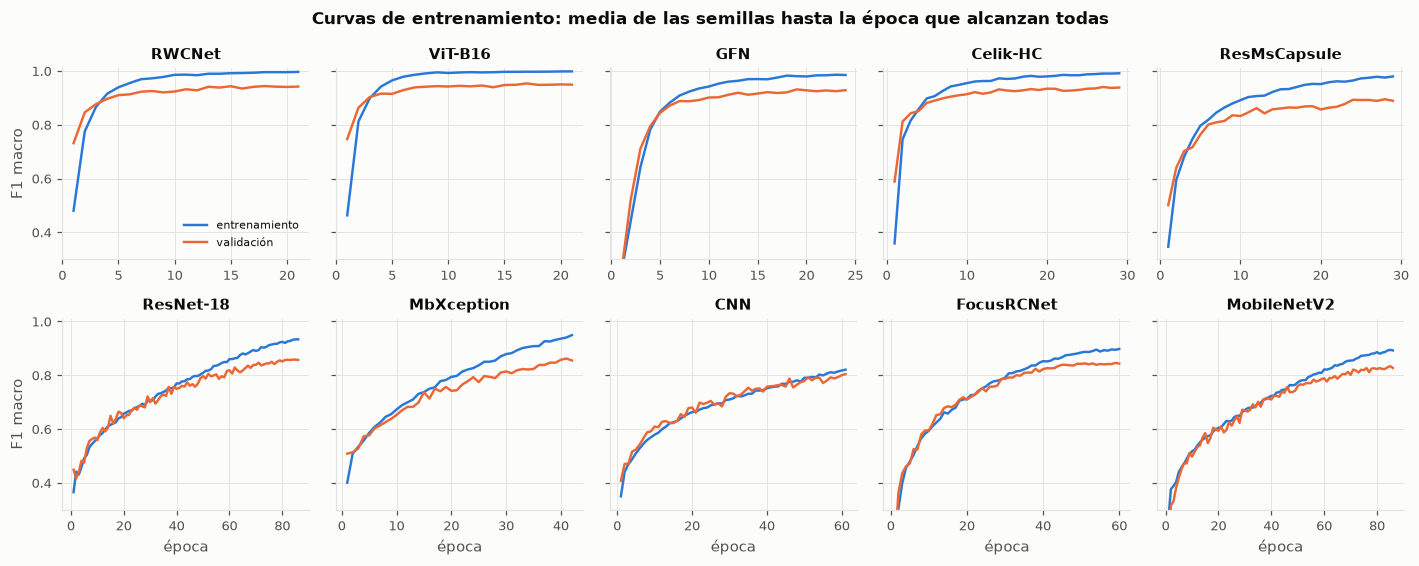

In [4]:
hist = {m: [load_pickle(run_dir(m, s) / "history.pkl") for s in SEEDS] for m in MODELS}
fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), sharey=True)
for ax, m in zip(axes.ravel(), w_order := list(pd.read_csv(SUM / "f1_macro_por_semilla.csv")[MODELS].mean().sort_values(ascending=False).index)):
    L = min(len(h["val_f1_macro"]) for h in hist[m])
    tr = np.mean([h["train_f1_macro"][:L] for h in hist[m]], 0)
    va = np.mean([h["val_f1_macro"][:L] for h in hist[m]], 0)
    ax.plot(range(1, L + 1), tr, color=FG.SERIES[0], lw=1.6, label="entrenamiento")
    ax.plot(range(1, L + 1), va, color=FG.SERIES[1], lw=1.6, label="validación")
    ax.set_title(m, fontsize=9.5); ax.set_ylim(0.3, 1.01)
axes[0, 0].set_ylabel("F1 macro"); axes[1, 0].set_ylabel("F1 macro")
for ax in axes[1]: ax.set_xlabel("época")
axes[0, 0].legend(loc="lower right", fontsize=7.5)
fig.suptitle("Curvas de entrenamiento: media de las semillas hasta la época que alcanzan todas", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

Seis modelos tienen una brecha significativamente menor que $\delta_g$ tras Holm: Celik-HC, ViT-B16, GFN, RWCNet y la CNN con las dos pruebas, y FocusRCNet con la t. Los demás quedan por encima o no se puede afirmar que estén por debajo:

- **ResNet-18:** 0.065;
- **MbXception:** 0.079;
- **ResMsCapsule:** 0.057;
- **MobileNetV2:** 0.039, pero con una dispersión que impide concluir.

Las curvas añaden un diagnóstico de subajuste. MbXception y FocusRCNet, entrenados desde cero, llegan al tope de 60 épocas en 6 y 8 de sus 8 semillas, con el F1 de validación todavía en aumento. Estos dos modelos son los candidatos naturales a un presupuesto de épocas mayor. Los modelos preentrenados alcanzan su mejor época entre la 20 y la 30 y se detienen por paciencia.

**Validación frente a prueba.** La diferencia $F1_{\text{val}} - F1_{\text{test}}$ indica sobreajuste a la validación por la selección de época e hiperparámetros, o un cambio de distribución entre los dos conjuntos. Calculamos su IC 95 % remuestreando grupos de casi-duplicados de ambos conjuntos (2000 remuestreos) y promediando las 8 semillas.

In [5]:
vt = pd.read_csv(COMP / "validacion_vs_prueba.csv").set_index("model")
display(vt.round(4))
cv = pd.read_csv(COMP / "sensibilidad_semilla.csv").set_index("model")
display(cv.round(4).T)

,val_menos_test,ic_lo,ic_hi,significativa
model,,,,
Celik-HC,0.0267,-0.0062,0.0581,False
MbXception,0.0197,-0.0294,0.0673,False
ViT-B16,0.0302,0.0034,0.0566,True
GFN,0.0331,0.0041,0.0616,True
FocusRCNet,0.0436,-0.0085,0.0910,False
ResMsCapsule,0.0240,-0.0142,0.0615,False
RWCNet,0.0122,-0.0156,0.0385,False
CNN,0.0245,-0.0297,0.0745,False
MobileNetV2,0.0385,-0.0131,0.0892,False


model,Celik-HC,MbXception,ViT-B16,GFN,FocusRCNet,ResMsCapsule,RWCNet,CNN,MobileNetV2,ResNet-18
media,0.9139,0.8613,0.9378,0.9210,0.8112,0.8990,0.9450,0.8261,0.8095,0.8628
de,0.0134,0.0137,0.0138,0.0147,0.0154,0.0153,0.0101,0.0215,0.0250,0.0216
cv_pct,1.4636,1.5939,1.4668,1.6008,1.8952,1.7069,1.0660,2.6057,3.0885,2.4990


El F1 de validación supera al de prueba en los diez modelos, entre 0.010 y 0.044. El IC excluye el cero solo en ViT-B16 (0.030) y GFN (0.033). La auditoría de la sección 9.3 detectó una diferencia leve de distribución entre validación y prueba (AUC adversarial de 0.56), así que parte de esta brecha no se debe a la selección. Todos los modelos se seleccionaron sobre el mismo conjunto de validación, por lo que el sesgo afecta por igual a la comparación.

**Sensibilidad a la semilla.** El coeficiente de variación entre semillas va de 1.1 % (RWCNet) a 3.1 % (MobileNetV2). Es menor en los modelos preentrenados, que parten de los mismos pesos y difieren solo en la cabeza, el orden de los lotes y el aumento.

## 14.3 Calibración

Reportamos el ECE con 15 bins de igual ancho, que es el preregistrado. Como el ECE depende de la discretización, añadimos un ECE adaptativo (15 bins de igual masa) y un ECE por clase. El escalado de temperatura divide los *logits* por un escalar $T$ ajustado en validación, $p = \mathrm{softmax}(z/T)$; no se aplica a Celik-HC, cuyas probabilidades vienen de XGBoost, ni a los modelos del capítulo 4.

In [6]:
ca = pd.read_csv(COMP / "calibracion_ampliada.csv")
display(ca.groupby("model", sort=False)[["ece15", "ece_adaptativo15", "ece_por_clase", "nll", "brier", "temperatura", "ece15_ts",
                                        "ece_adaptativo15_ts"]].mean().round(4))

,ece15,ece_adaptativo15,ece_por_clase,nll,brier,temperatura,ece15_ts,ece_adaptativo15_ts
model,,,,,,,,
Celik-HC,0.0563,0.0494,0.0215,0.3627,0.1250,NaN,NaN,NaN
MbXception,0.0571,0.0517,0.0313,0.4334,0.1908,1.5288,0.0346,0.0380
ViT-B16,0.0416,0.0354,0.0179,0.2380,0.0936,1.3786,0.0302,0.0303
GFN,0.0510,0.0485,0.0204,0.3145,0.1100,1.5305,0.0329,0.0388
FocusRCNet,0.1317,0.1262,0.0508,1.0390,0.2907,3.1550,0.0430,0.0432
ResMsCapsule,0.1934,0.1911,0.0709,0.4505,0.1887,0.5143,0.0283,0.0327
RWCNet,0.0273,0.0213,0.0161,0.1754,0.0779,1.2763,0.0202,0.0172
CNN,0.0602,0.0612,0.0378,0.4850,0.2351,NaN,NaN,NaN
MobileNetV2,0.0705,0.0656,0.0358,0.5500,0.2522,NaN,NaN,NaN


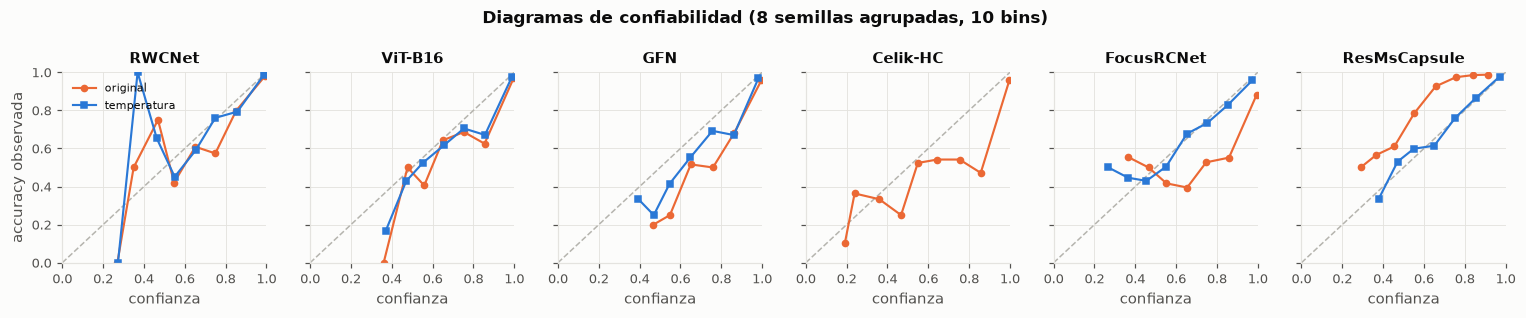

In [7]:
def reliab(P, y, bins=10):
    conf = P.max(1); acc = (P.argmax(1) == y)
    e = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(conf, e) - 1, 0, bins - 1)
    return np.array([[conf[idx == b].mean(), acc[idx == b].mean(), (idx == b).sum()] if (idx == b).any() else [np.nan] * 3 for b in range(bins)])

sel = ["RWCNet", "ViT-B16", "GFN", "Celik-HC", "FocusRCNet", "ResMsCapsule"]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.9), sharey=True)
for ax, m in zip(axes, sel):
    Ps, Ys, Pts = [], [], []
    for s in SEEDS:
        d = aligned(m, s); Ps.append(d["probs"]); Ys.append(d["y_true"])
        c = load_pickle(run_dir(m, s) / "calibration.pkl")
        if c.get("aplicable") and "probs_escaladas" in c:
            d0 = load_pickle(run_dir(m, s) / "test_predictions.pkl"); o = np.argsort([relpath(f) for f in d0["filepaths"]])
            Pts.append(c["probs_escaladas"][o])
    r = reliab(np.concatenate(Ps), np.concatenate(Ys))
    ax.plot([0, 1], [0, 1], color=FG.NEUTRAL, lw=1, ls="--")
    ax.plot(r[:, 0], r[:, 1], "o-", color=FG.SERIES[1], ms=4, lw=1.4, label="original")
    if Pts:
        rt = reliab(np.concatenate(Pts), np.concatenate(Ys))
        ax.plot(rt[:, 0], rt[:, 1], "s-", color=FG.SERIES[0], ms=4, lw=1.4, label="temperatura")
    ax.set_title(m, fontsize=9.5); ax.set_xlabel("confianza"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("accuracy observada"); axes[0].legend(loc="upper left", fontsize=7.5)
fig.suptitle("Diagramas de confiabilidad (8 semillas agrupadas, 10 bins)", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

RWCNet es el modelo mejor calibrado: tiene el menor ECE fijo (0.027), adaptativo (0.021) y por clase (0.016), y la menor NLL (0.175). El escalado de temperatura reduce el ECE de todos los modelos a los que se aplica, hasta 0.020–0.043, y corrige los dos extremos:

- **FocusRCNet:** su ECE baja de 0.132 a 0.043 con $T = 3.2$.
- **ResMsCapsule:** baja de 0.193 a 0.028 con $T = 0.51$, porque una temperatura menor que 1 agudiza una salida subconfiada.

El ECE fijo y el adaptativo ordenan los modelos de la misma forma, por lo que la conclusión no depende de la discretización.

## 14.4 Incertidumbre predictiva

**MC Dropout (preregistrado).** Con 20 pasadas estocásticas por imagen, descomponemos la entropía predictiva en una parte aleatoria y otra epistémica, la información mutua $I = H[\bar p] - \overline{H[p]}$. Una incertidumbre útil debe ser mayor en los errores que en los aciertos.

In [8]:
mcd = pd.read_csv(SUM / "incertidumbre_mc_dropout.csv")
u = mcd.groupby("model", sort=False)[["mi_media_aciertos", "mi_media_errores", "f1_macro_determinista", "mc_f1_macro", "mc_ece"]].mean()
u["razón errores/aciertos"] = u.mi_media_errores / u.mi_media_aciertos
display(u.round(4))

,mi_media_aciertos,mi_media_errores,f1_macro_determinista,mc_f1_macro,mc_ece,razón errores/aciertos
model,,,,,,
Celik-HC,0.0075,0.0581,0.9139,0.9177,0.0539,7.7012
MbXception,0.0033,0.0125,0.8613,0.8602,0.0573,3.8067
ViT-B16,0.0012,0.0107,0.9378,0.9391,0.0418,9.0244
GFN,0.0010,0.0113,0.9210,0.9217,0.0488,11.1593
FocusRCNet,0.0063,0.0281,0.8112,0.8105,0.1276,4.4327
ResMsCapsule,0.0131,0.0199,0.8990,0.9005,0.1960,1.5172
RWCNet,0.0008,0.0068,0.9450,0.9443,0.0290,8.1021


En los siete modelos con capas de *dropout*, la información mutua es mayor en los errores que en los aciertos. La razón va de 1.5 (ResMsCapsule) a 11 (GFN) y es de 8 a 9 en ViT-B16 y RWCNet. Promediar las 20 pasadas no cambia el F1 de forma apreciable (≤ 0.004). Los modelos del capítulo 4 no guardaron MC Dropout.

**Predicción conforme (exploratoria).** Para los diez modelos aplicamos predicción conforme dividida con dos puntajes:

- **LAC:** $1 - \hat p_y$;
- **APS:** masa acumulada hasta la clase verdadera, sin aleatorización.

Calibramos el umbral con el conjunto de validación de la misma corrida, disjunto del de entrenamiento y del de prueba, y medimos en prueba la cobertura empírica y el tamaño medio del conjunto para $\alpha = 0.10$ y $0.05$.

In [9]:
cf = pd.read_csv(COMP / "conforme.csv")
t = cf.groupby(["model", "alpha"], sort=False)[["cobertura_lac", "tam_medio_lac", "vacios_lac", "cobertura_aps", "tam_medio_aps"]].mean().unstack()
display(t.round(3))
cc = pd.read_csv(COMP / "conforme_por_clase.csv")
display(cc[cc.model.isin(["RWCNet", "ViT-B16", "GFN"])].groupby(["model", "clase"]).cobertura_lac.mean().unstack().round(3))

cobertura_lac        tam_medio_lac        vacios_lac         \
alpha                 0.10   0.05          0.10   0.05       0.10   0.05   
model                                                                      
Celik-HC             0.877  0.935         0.907  1.030      0.093  0.007   
MbXception           0.903  0.958         1.072  1.406      0.001  0.000   
ViT-B16              0.868  0.924         0.886  0.962      0.114  0.038   
GFN                  0.882  0.934         0.913  0.998      0.087  0.019   
FocusRCNet           0.894  0.949         1.230  1.620      0.000  0.000   
ResMsCapsule         0.886  0.954         0.954  1.165      0.052  0.001   
RWCNet               0.884  0.944         0.898  0.988      0.102  0.014   
CNN                  0.902  0.959         1.189  1.698      0.001  0.000   
MobileNetV2          0.896  0.948         1.202  1.560      0.000  0.000   
ResNet-18            0.916  0.961         1.130  1.463      0.000  0.000   

             cobertura_aps        tam_medio_aps         
alpha                 0.10   0.05          0.10   0.05  
model                                                   
Celik-HC             0.992  0.992         2.817  2.866  
MbXception           0.997  0.998         3.926  4.596  
ViT-B16              0.998  0.998         3.089  3.322  
GFN                  0.996  0.997         2.904  3.097  
FocusRCNet           0.997  0.999         4.360  4.896  
ResMsCapsule         0.984  0.988         2.539  2.887  
RWCNet               1.000  1.000         4.468  4.958  
CNN                  0.997  0.999         4.275  4.796  
MobileNetV2          0.997  0.999         4.029  4.559  
ResNet-18            0.997  0.999         3.931  4.548

clase,cardboard,glass,metal,paper,plastic,trash
model,,,,,,
GFN,0.922,0.877,0.927,0.925,0.810,0.717
RWCNet,0.901,0.882,0.920,0.929,0.810,0.796
ViT-B16,0.931,0.861,0.866,0.924,0.808,0.678


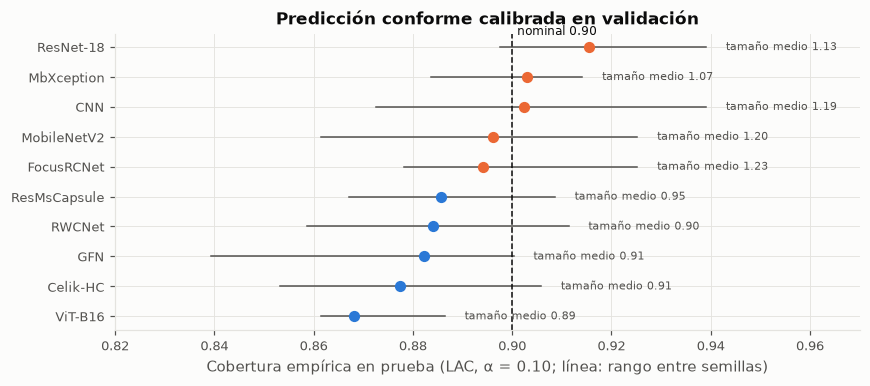

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sub = cf[cf.alpha == 0.10]
orden = sub.groupby("model").cobertura_lac.mean().sort_values().index
for i, m in enumerate(orden):
    x = sub[sub.model == m].cobertura_lac
    ax.plot([x.min(), x.max()], [i, i], color=FG.INK2, lw=1)
    ax.scatter(x.mean(), i, color=FG.color_regimen(m), s=40, zorder=3)
    ax.text(x.max() + 0.004, i, f"tamaño medio {sub[sub.model == m].tam_medio_lac.mean():.2f}", va="center", fontsize=7.5, color=FG.INK2)
ax.axvline(0.90, color=FG.INK, lw=1, ls="--"); ax.text(0.901, len(orden) - 0.6, "nominal 0.90", fontsize=8)
ax.set_yticks(range(len(orden)), orden); ax.set_xlim(0.82, 0.97)
ax.set_xlabel("Cobertura empírica en prueba (LAC, α = 0.10; línea: rango entre semillas)")
ax.set_title("Predicción conforme calibrada en validación")
plt.tight_layout(); plt.show()

Con LAC y $\alpha = 0.10$, la cobertura media va de 0.868 (ViT-B16) a 0.916 (ResNet-18), alrededor del nominal de 0.90. Los mejores modelos producen conjuntos de 0.89 a 0.91 clases en promedio, es decir, casi siempre una sola clase y a veces el conjunto vacío. Los modelos más débiles necesitan 1.1 a 1.2 clases.

Los modelos preentrenados quedan algo por debajo del nominal, y lo atribuimos a dos causas. La garantía de la predicción conforme exige que validación y prueba sean intercambiables, y la sección 9.3 encontró una diferencia leve entre ambas. Además, estos modelos tienen el F1 de validación más optimista (sección 14.2).

APS, sin aleatorización, sobrecubre (≥ 0.98) con conjuntos de 2.5 a 5 clases, por lo que no es útil aquí. La cobertura por clase muestra que el déficit se concentra en `trash` (0.68 a 0.80) y `plastic` (0.81), las clases más difíciles (capítulo 15).

## 14.5 Criterio de adecuación

Un modelo es adecuado si cumple a la vez las cuatro condiciones:

- **(i)** supera al baseline trivial con $p$ ajustado < 0.05 y por más de $\delta$;
- **(ii)** su brecha entre entrenamiento y validación es menor que $\delta_g$ con evidencia estadística;
- **(iii)** sus probabilidades están calibradas;
- **(iv)** su F1 de prueba es consistente con el de validación.

Para (iii) usamos el ECE tras el escalado de temperatura con un umbral de 0.05, fijado aquí y no en el preregistro. Para (iv), el IC de la diferencia entre validación y prueba debe incluir el cero.

In [11]:
crit = pd.DataFrame(index=MODELS)
crit["(i) supera al trivial"] = True
crit["(ii) brecha < δg (Holm)"] = [(br.loc[m, "p_t_holm"] < 0.05) for m in MODELS]
ece_ts = ca.groupby("model").ece15_ts.mean()
crit["(iii) calibrado (ECE tras temperatura < 0.05)"] = [bool(ece_ts.get(m) < 0.05) if not np.isnan(ece_ts.get(m, np.nan)) else
                                                       ("sin recalibrar: " + f"{ca[ca.model == m].ece15.mean():.3f}") for m in MODELS]
crit["(iv) val ≈ prueba"] = [not bool(vt.loc[m, "significativa"]) for m in MODELS]
display(crit)

,(i) supera al trivial,(ii) brecha < δg (Holm),(iii) calibrado (ECE tras temperatura < 0.05),(iv) val ≈ prueba
Celik-HC,True,True,sin recalibrar: 0.056,True
MbXception,True,False,True,True
ViT-B16,True,True,True,False
GFN,True,True,True,False
FocusRCNet,True,True,True,True
ResMsCapsule,True,False,True,True
RWCNet,True,True,True,True
CNN,True,True,sin recalibrar: 0.060,True
MobileNetV2,True,False,sin recalibrar: 0.070,True
ResNet-18,True,False,sin recalibrar: 0.051,True


Dos modelos cumplen las cuatro condiciones, y solo uno de ellos es competitivo:

- **RWCNet** cumple las cuatro condiciones, con la menor diferencia entre validación y prueba del benchmark (0.012, IC [−0.016, 0.039]).
- **FocusRCNet** también las cumple formalmente, aunque su brecha solo es menor que $\delta_g$ con la t (no con Wilcoxon). Es el modelo con menor F1 del grupo y llega al tope de épocas en todas sus semillas: es adecuado en el sentido de la sección 7.2, pero no competitivo.
- **ViT-B16 y GFN** cumplen (i) a (iii) y fallan (iv) por un sesgo de validación pequeño pero significativo.
- **Celik-HC** cumple (i), (ii) y (iv), pero no se puede recalibrar con temperatura y su ECE original es 0.056.

- **ResMsCapsule** cumple (i), (iii) y (iv), pero su brecha entre entrenamiento y validación (0.057) supera $\delta_g$.
- **Modelos base y MbXception:** MbXception, MobileNetV2 y ResNet-18 fallan (ii). La CNN cumple (i), (ii) y (iv), pero sus probabilidades sin recalibrar (ECE de 0.060) no cumplen (iii).